# Imports

In [1]:
import os, sys
sys.path.append("D:\\DATA\\ETL_PIC\\simulation\\")
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
matplotlib.rc_file('D:\\DATA\\ETL_PIC\\matplotlibrc.txt')
import pandas as pd
from tqdm import tqdm

import rsoft_lib as rlib
from rsoft_lib.device_setup import SIM, DESIGN_WAVELENGTH, WIDTH, device_paths, export_device

# Design device

One arm has a delay bump, the other arm is straight but tapers to different widths with cosine tapers.

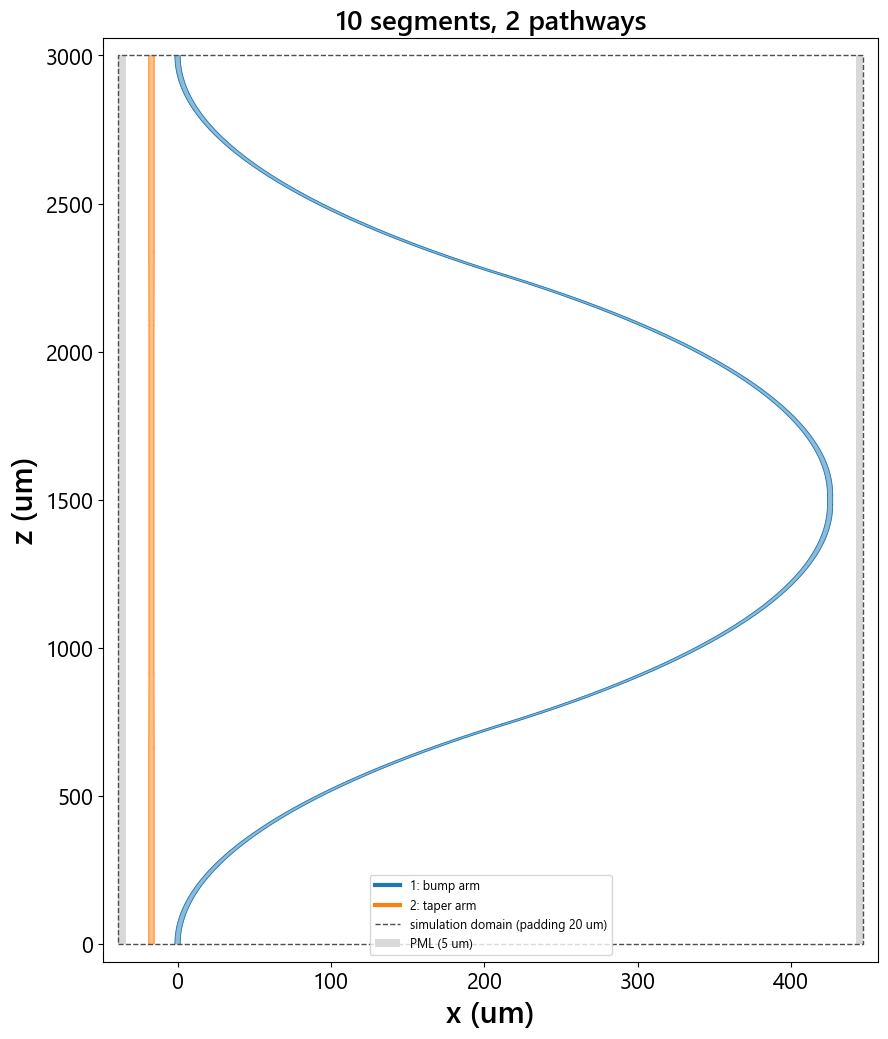

P-07a_WidthMZI: bump arm - straight arm = 160.000000 μm, excursion 425.3 μm, width section 3.2 μm x 1176 μm with 250 μm tapers
Wrote D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-07_WidthMZI\P-07a_WidthMZI.ind and D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-07_WidthMZI\P-07a_WidthMZI.gds; 30000 propagation steps per wavelength


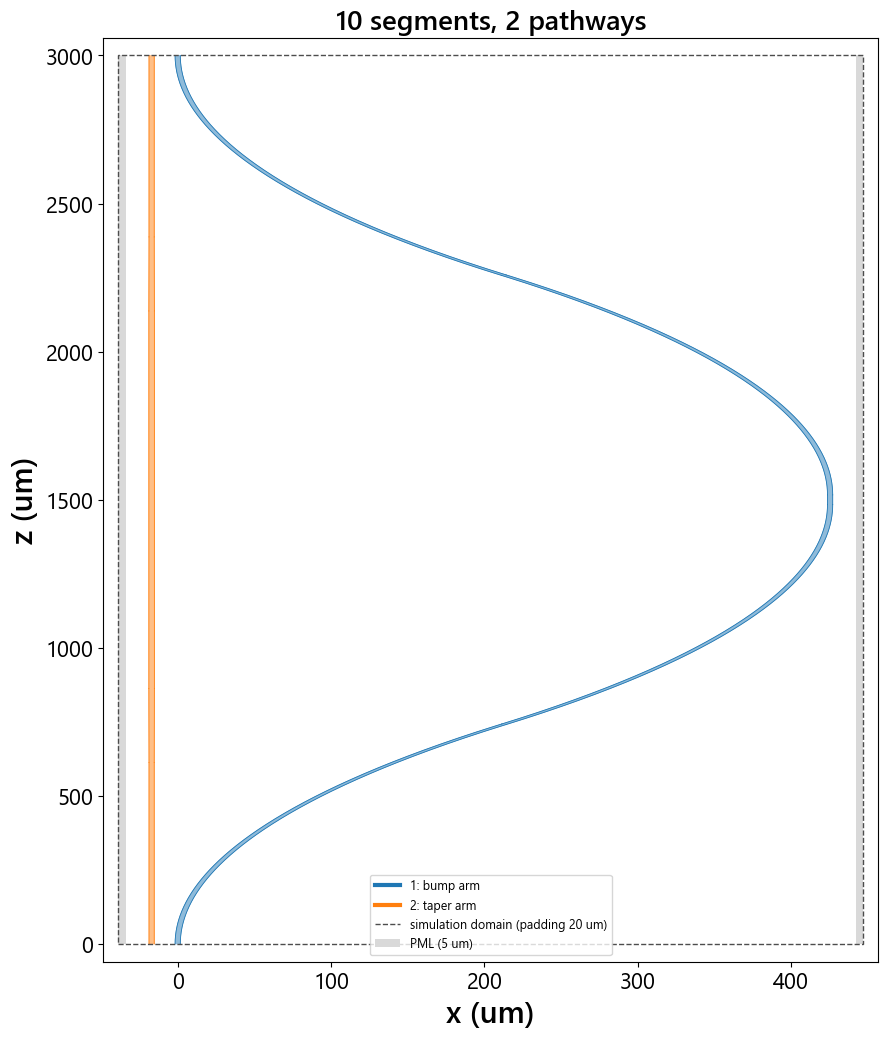

P-07b_WidthMZI: bump arm - straight arm = 160.000000 μm, excursion 425.3 μm, width section 3.6 μm x 1275 μm with 250 μm tapers
Wrote D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-07_WidthMZI\P-07b_WidthMZI.ind and D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-07_WidthMZI\P-07b_WidthMZI.gds; 30000 propagation steps per wavelength


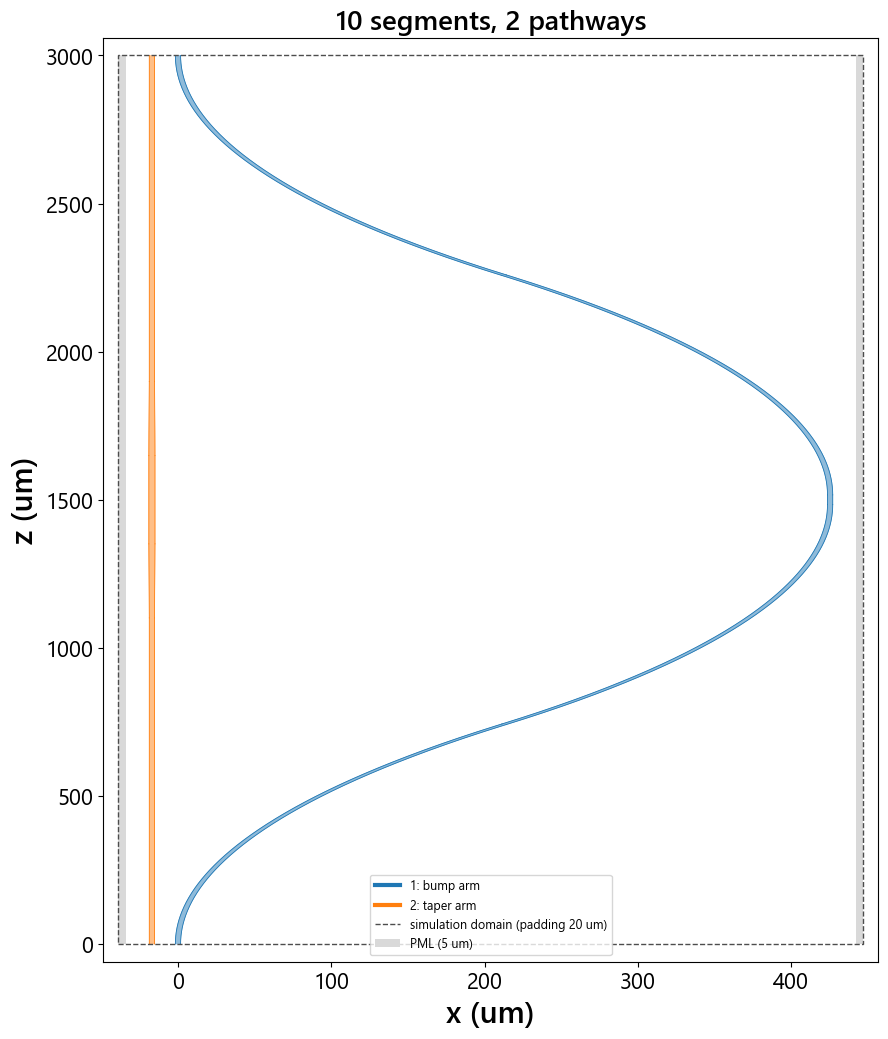

P-07c_WidthMZI: bump arm - straight arm = 160.000000 μm, excursion 425.3 μm, width section 4 μm x 298 μm with 250 μm tapers
Wrote D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-07_WidthMZI\P-07c_WidthMZI.ind and D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-07_WidthMZI\P-07c_WidthMZI.gds; 30000 propagation steps per wavelength


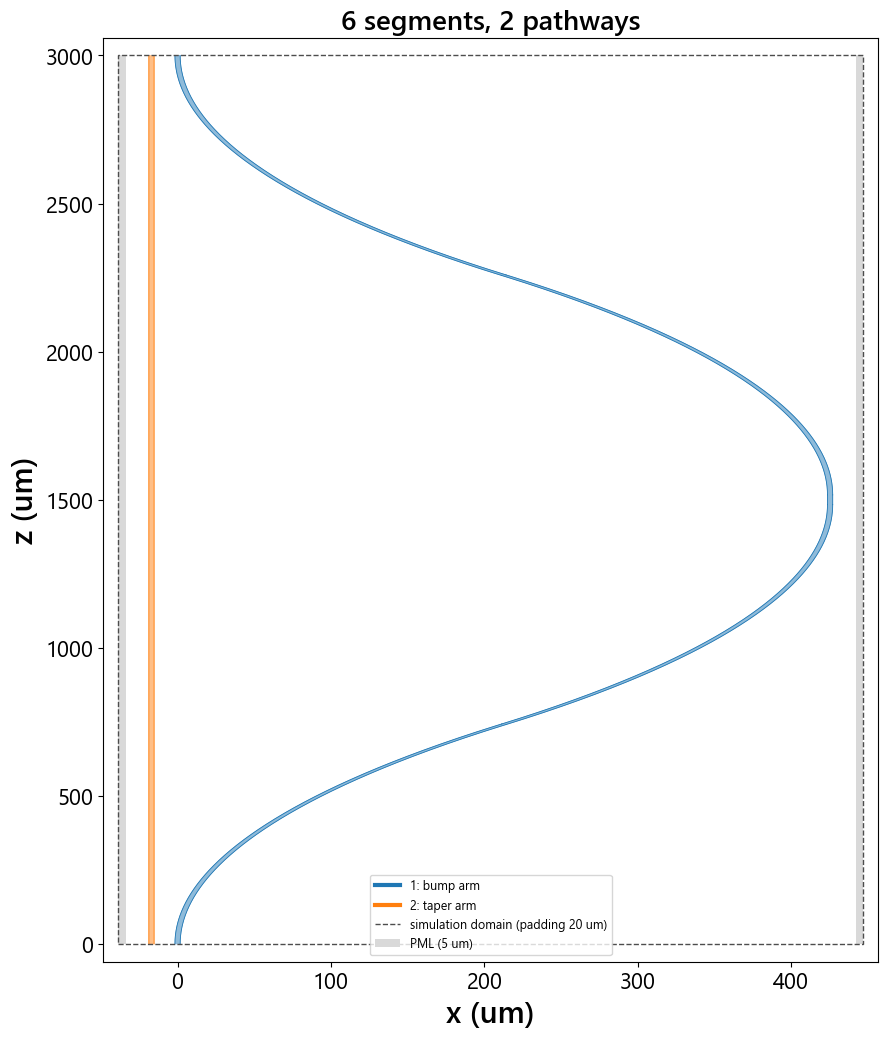

P-07ref_WidthMZI: bump arm - straight arm = 160.000000 μm, excursion 425.3 μm, plain straight arm
Wrote D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-07_WidthMZI\P-07ref_WidthMZI.ind and D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-07_WidthMZI\P-07ref_WidthMZI.gds; 30000 propagation steps per wavelength


In [4]:
# Set up directories
device_name = 'P-07_WidthMZI'
device_dir = f"D:\\DATA\\ETL_PIC\\simulation\\NullingPIC_Gen2_sims\\{device_name}\\"

# Set up parameters
z_length = 3000.0               # length of both arms in z (um); the bump needs at least 2967.1 um
deltaL = 160.0                  # bump arm - straight arm path length (um)
bump_radius = 1400.0            # radius of the bump's arcs (um)
arm_pitch = 17.0                # straight arm, this far on the -x side of the bump arm (um)
taper_length = 250.0            # linear tapers at each end of the width section (um)

# Straight-arm width section of each variant: (width w (um), length L_w (um)), None for a plain straight arm
variants = {
    "P-07a_WidthMZI": (3.2, 1176.0),
    "P-07b_WidthMZI": (3.6, 1275),
    "P-07c_WidthMZI": (4.0, 298),
    "P-07ref_WidthMZI": None,
}
pathway_labels = ["bump arm", "taper arm"]

# The bump arm, IDENTICAL in every variant: S-bend out, straight, S-bend back
xb, zb, pb = rlib.delay_arm(z_length, deltaL, bump_radius, end_straight=0, x0=0.0, direction=1)

circuits = {}
for variant_name, section in variants.items():
    paths = device_paths(device_dir, variant_name)
    c = rlib.Circuit(width=WIDTH, orientation="extended")

    # Pathway 1, bump arm
    bump = c.add_path(xb, zb, pb)
    c.add_pathway(bump["segments"], launch=True)

    # Pathway 2, straight arm: WIDTH, linear taper to w, w over L_w, linear taper back, WIDTH (the section centered in z)
    x_s = -arm_pitch
    if section is None:
        straight = [c.line((x_s, 0.0), (x_s, z_length))]
    else:
        w, L_w = section
        z1 = (z_length - L_w - 2 * taper_length) / 2                  # where the first taper starts
        z2, z3, z4 = z1 + taper_length, z1 + taper_length + L_w, z1 + 2 * taper_length + L_w
        straight = [c.line((x_s, 0.0), (x_s, z1)),
                    c.line((x_s, z1), (x_s, z2), width=(WIDTH, w), profile="cosine"),
                    c.line((x_s, z2), (x_s, z3), width=w),
                    c.line((x_s, z3), (x_s, z4), width=(w, WIDTH), profile="cosine"),
                    c.line((x_s, z4), (x_s, z_length))]
    c.add_pathway(straight, launch=True)
    circuits[variant_name] = c

    # Export and visualize circuit
    export_device(c, paths)
    c.plot(labels=pathway_labels, figsize=(10, 12))      # after the export, so the plot shows the domain as written
    dL = c.path_length(c.pathways[0].segments) - c.path_length(c.pathways[1].segments)
    print(f"{variant_name}: bump arm - straight arm = {dL:.6f} μm, excursion {xb.max():.1f} μm, "
          + ("plain straight arm" if section is None else f"width section {section[0]:g} μm x {section[1]:g} μm with {taper_length:g} μm tapers"))
    print(f"Wrote {paths['ind']} and {paths['gds']}; {z_length / SIM['Step_z']:.0f} propagation steps per wavelength")

Visualize cosine tapers

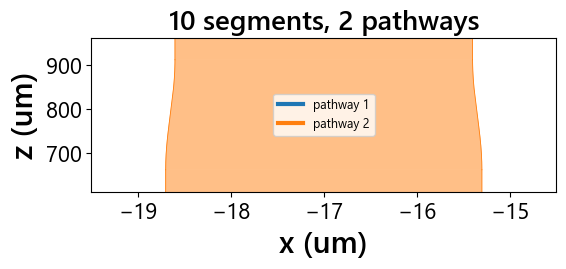

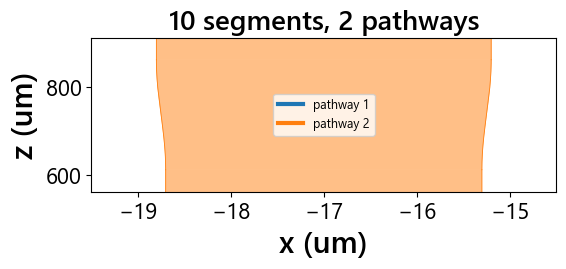

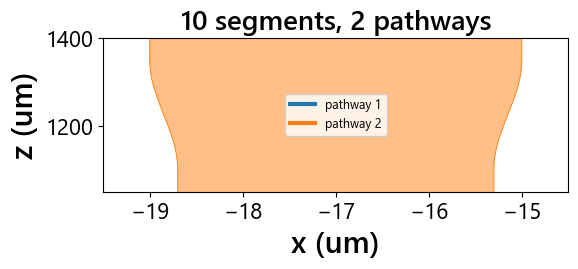

In [10]:
for i in range(3):
    c = circuits[f"P-07{chr(i+97)}_WidthMZI"]
    z1 = (z_length - variants[f"P-07{chr(i+97)}_WidthMZI"][1] - 2 * taper_length) / 2
    c.plot(xlim=(-arm_pitch - 2.5, -arm_pitch + 2.5), ylim=(z1 - 50, z1 + taper_length + 50), domain=False, figsize=(6, 2))

# Estimate interference pattern

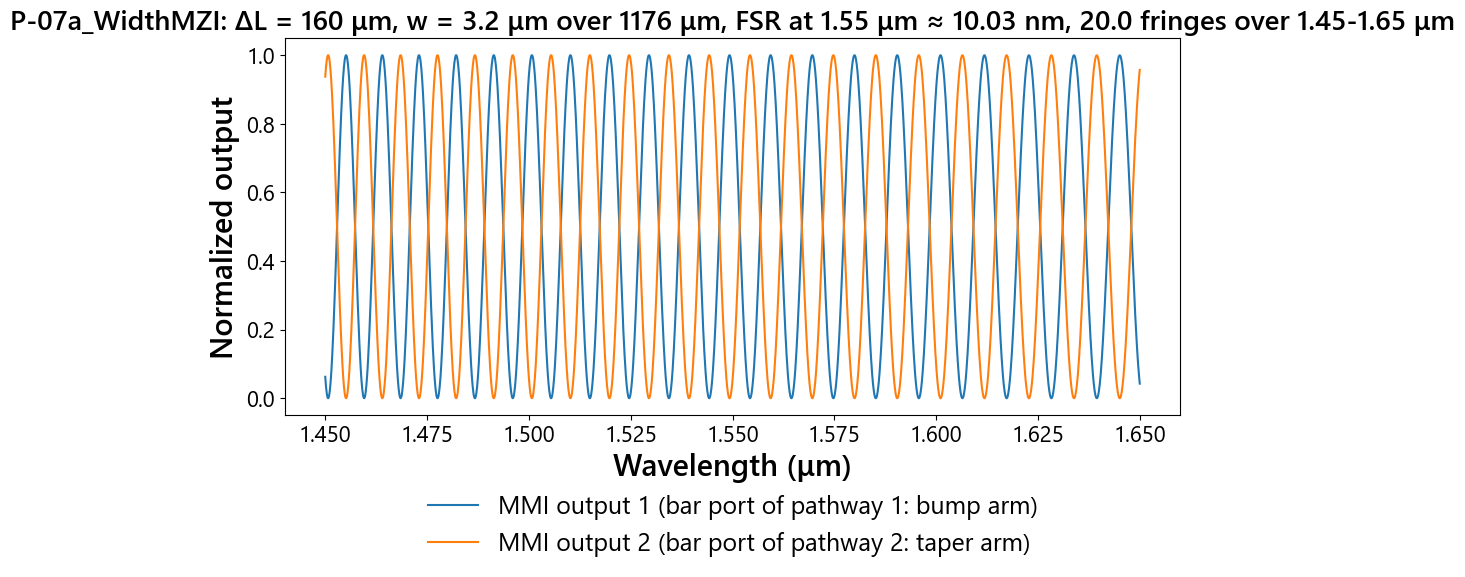

Wrote D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-07_WidthMZI\P-07ref_WidthMZI.ind and D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-07_WidthMZI\P-07ref_WidthMZI.gds; 30000 propagation steps per wavelength


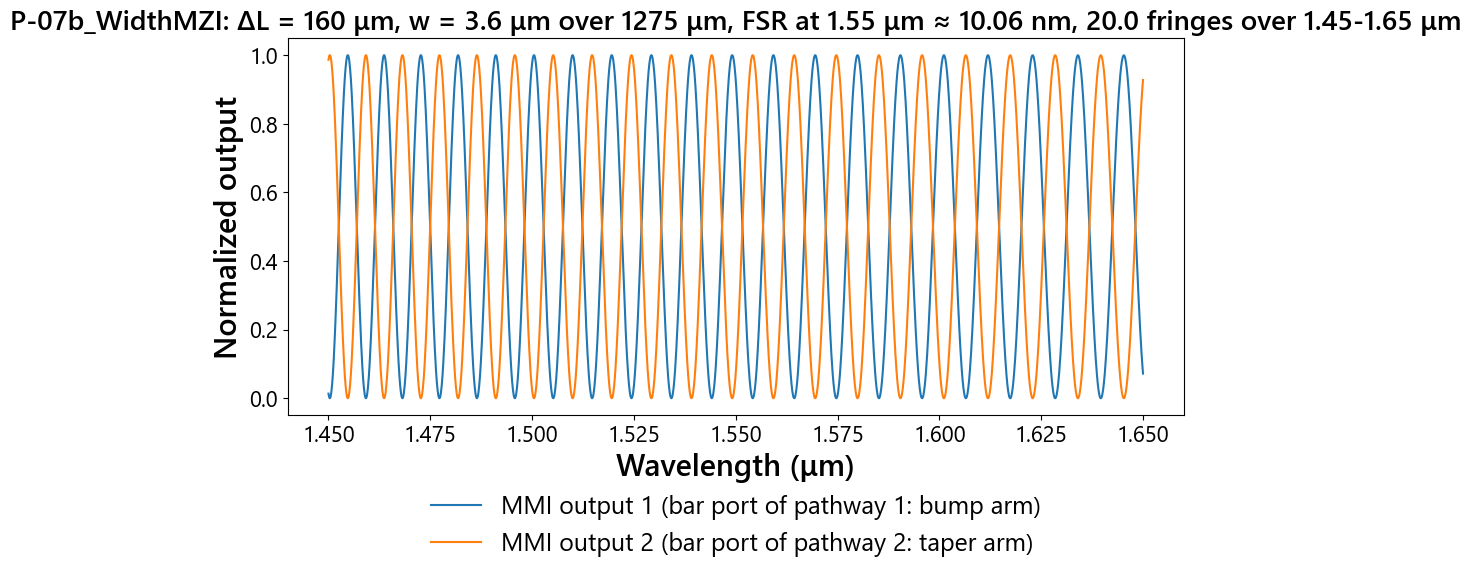

Wrote D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-07_WidthMZI\P-07ref_WidthMZI.ind and D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-07_WidthMZI\P-07ref_WidthMZI.gds; 30000 propagation steps per wavelength


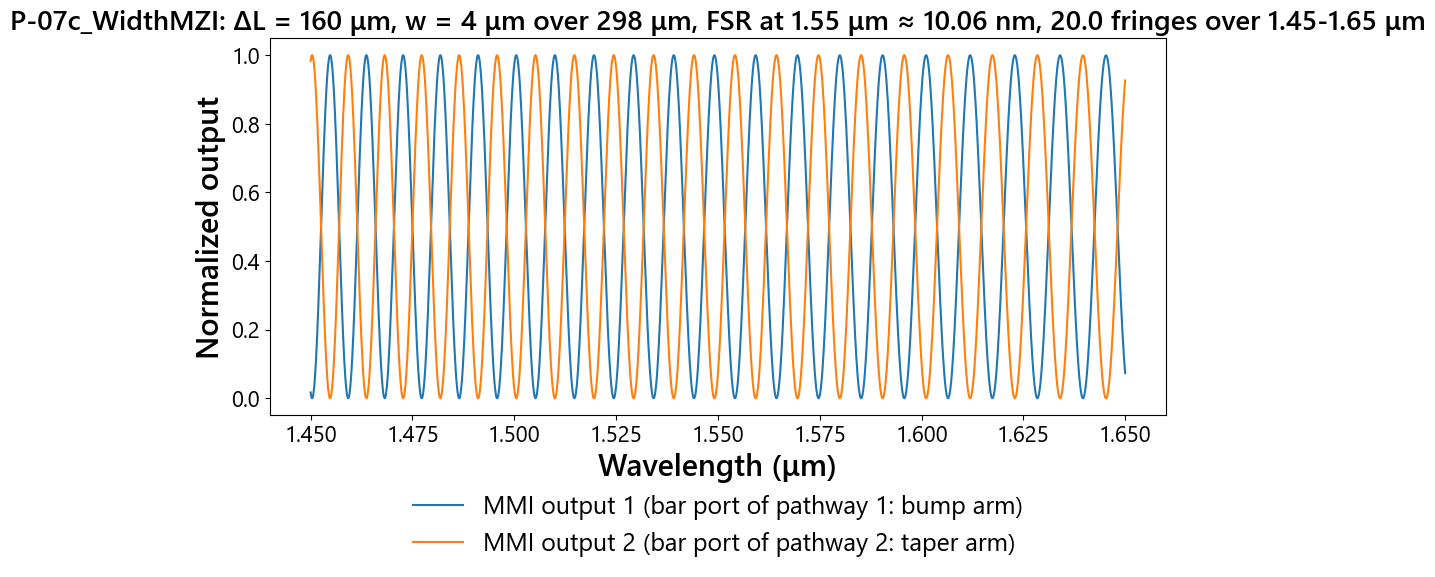

Wrote D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-07_WidthMZI\P-07ref_WidthMZI.ind and D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-07_WidthMZI\P-07ref_WidthMZI.gds; 30000 propagation steps per wavelength


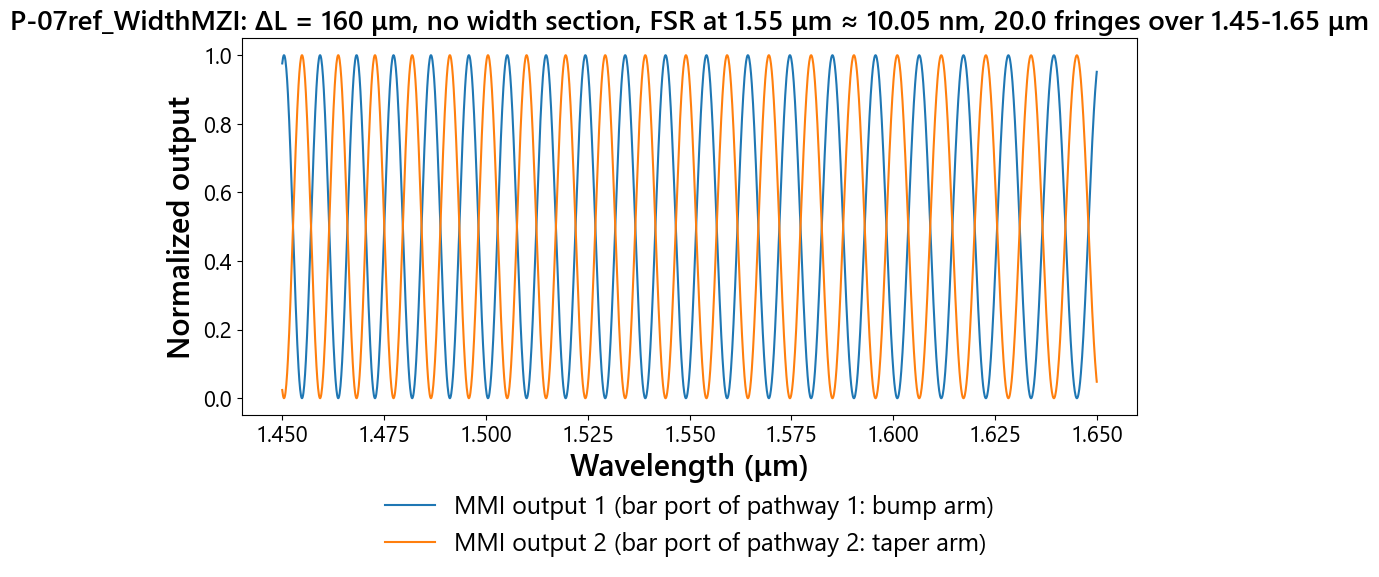

Wrote D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-07_WidthMZI\P-07ref_WidthMZI.ind and D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-07_WidthMZI\P-07ref_WidthMZI.gds; 30000 propagation steps per wavelength


In [12]:
# %% Interference spectrum of each circuit: Y-splitter, the two pathways, 2x2 MMI
wl = np.linspace(1.45, 1.65, 2001)
tm = rlib.transfer

for variant_name, c in circuits.items():
    section = variants[variant_name]
    est = rlib.estimate_pathways(c, wl)
    arm_a = tm.pathway(est, 1)                          # pathway 1: bump arm
    arm_b = tm.pathway(est, 2)                          # pathway 2: straight arm
    T = tm.mzi_response(wl, arm_a, arm_b, splitter="y", combiner="mmi")
    P = tm.power(T)                                     # (wavelengths, 2 outputs)
    dphi = est.difference(1, 2)["phase"]                # bump arm - straight arm
    n_fringes = abs(dphi[0] - dphi[-1]) / (2 * np.pi)
    fsr = tm.fsr(wl, dphi)

    plt.figure(figsize=(10, 6))
    plt.plot(wl, P[:, 0], label=f"MMI output 1 (bar port of pathway 1: {pathway_labels[0]})")
    plt.plot(wl, P[:, 1], label=f"MMI output 2 (bar port of pathway 2: {pathway_labels[1]})")
    plt.xlabel('Wavelength (μm)')
    plt.ylabel('Normalized output')
    plt.title(f"{variant_name}: ΔL = {deltaL:g} μm, " + ("no width section" if section is None else f"w = {section[0]:g} μm over {section[1]:g} μm")
              + f", FSR at 1.55 μm ≈ {np.interp(1.55, wl, fsr) * 1e3:.2f} nm, {n_fringes:.1f} fringes over {wl[0]:g}-{wl[-1]:g} μm")
    plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=1, frameon=False)
    plt.tight_layout()
    plt.show()
    print(f"Wrote {paths['ind']} and {paths['gds']}; {z_length / SIM['Step_z']:.0f} propagation steps per wavelength")